# CalSymPy (Team 4, Delta-T) — Fallback Demo Notebook
### MAT 112 Engineering Mathematics & Python

This standalone Google Colab / Jupyter notebook contains the complete **CalSymPy** project.
All temperature models and calculus tools are self-contained in this notebook — no external files, tkinter, or custom libraries required.

**Contents:**
1. Setup and Libraries
2. Temperature Models & Hand-Derived Derivatives (from `models.py`)
3. Calculus Tools (from `calculus.py`)
4. Point Lookup & Second Derivative Test
5. Hottest Point Grid Search & Risk Assessment
6. Average Temperature (Midpoint Riemann Sum)
7. Gradient Descent (Chip Cooling Simulation)
8. Visualizations: Static Heat Map & Quiver Plot
9. Visualizations: Cooling Trajectory Plot


In [1]:
# Cell 1: Setup and Libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

print('Libraries imported successfully!')


Libraries imported successfully!


## 1. Temperature Models and Hand-Derived Derivatives
This cell contains the exact temperature formulas and hand-derived partial derivatives from `models.py`:
- **Model A**: Single Gaussian hotspot ($T = T_{\text{edge}} + T_0 \exp(-r^2/s)$)
- **Model B**: Sine standing wave plate ($T = T_{\text{edge}} + T_0 \sin(\pi x/L) \sin(\pi y/L)$)
- **Model C**: Two Gaussian hotspots (sum of two Gaussians)
- **Plate**: Simple class to store plate dimensions and parameters


In [2]:
# models.py - temperature formulas and hand-derived derivatives
import numpy as np

# Model A: Single hotspot
# Formula: T = T_edge + T0 * exp(-r^2 / s) where r^2 = (x-cx)^2 + (y-cy)^2
def temp_a(x, y, t_edge=25.0, t0=60.0, s=2.0, cx=2.0, cy=2.0):
    # Gaussian heat source in the center
    r2 = (x - cx) ** 2 + (y - cy) ** 2
    return t_edge + t0 * np.exp(-r2 / s)

def grad_a(x, y, t_edge=25.0, t0=60.0, s=2.0, cx=2.0, cy=2.0):
    # d/dx exp(-u) = -exp(-u) * du/dx, where u = r^2 / s
    # Tx = T0 * exp(-r2/s) * (-2*(x-cx)/s)
    r2 = (x - cx) ** 2 + (y - cy) ** 2
    factor = t0 * np.exp(-r2 / s) * (-2.0 / s)
    tx = factor * (x - cx)
    ty = factor * (y - cy)
    return tx, ty

def hessian_a(x, y, t_edge=25.0, t0=60.0, s=2.0, cx=2.0, cy=2.0):
    # Product rule on Tx: d/dx [factor * (x-cx)]
    # Txx = T0*exp(-r2/s) * (4*(x-cx)^2/s^2 - 2/s)
    # Txy = T0*exp(-r2/s) * (4*(x-cx)*(y-cy)/s^2)
    r2 = (x - cx) ** 2 + (y - cy) ** 2
    e = t0 * np.exp(-r2 / s)
    txx = e * (4.0 * ((x - cx) ** 2) / (s ** 2) - 2.0 / s)
    tyy = e * (4.0 * ((y - cy) ** 2) / (s ** 2) - 2.0 / s)
    txy = e * (4.0 * (x - cx) * (y - cy) / (s ** 2))
    return txx, tyy, txy

# Model B: Sine plate
# Formula: T = T_edge + T0 * sin(pi*x/L) * sin(pi*y/L)
def temp_b(x, y, t_edge=20.0, t0=50.0, L=4.0):
    # Standing wave temperature pattern
    u = np.pi * x / L
    v = np.pi * y / L
    return t_edge + t0 * np.sin(u) * np.sin(v)

def grad_b(x, y, t_edge=20.0, t0=50.0, L=4.0):
    # d/dx sin(pi*x/L) = (pi/L)*cos(pi*x/L)
    u = np.pi * x / L
    v = np.pi * y / L
    tx = t0 * (np.pi / L) * np.cos(u) * np.sin(v)
    ty = t0 * (np.pi / L) * np.sin(u) * np.cos(v)
    return tx, ty

def hessian_b(x, y, t_edge=20.0, t0=50.0, L=4.0):
    # d/dx cos(pi*x/L) = -(pi/L)*sin(pi*x/L)
    u = np.pi * x / L
    v = np.pi * y / L
    factor = t0 * ((np.pi / L) ** 2)
    txx = -factor * np.sin(u) * np.sin(v)
    tyy = -factor * np.sin(u) * np.sin(v)
    txy = factor * np.cos(u) * np.cos(v)
    return txx, tyy, txy

# Model C: Two hotspots
# Formula: sum of two Gaussians
def temp_c(x, y, t_edge=25.0, t1=40.0, s1=1.5, cx1=1.2, cy1=1.2, t2=40.0, s2=1.5, cx2=2.8, cy2=2.8):
    # Two hot spots added together
    r1 = (x - cx1) ** 2 + (y - cy1) ** 2
    r2 = (x - cx2) ** 2 + (y - cy2) ** 2
    part1 = t1 * np.exp(-r1 / s1)
    part2 = t2 * np.exp(-r2 / s2)
    return t_edge + part1 + part2

def grad_c(x, y, t_edge=25.0, t1=40.0, s1=1.5, cx1=1.2, cy1=1.2, t2=40.0, s2=1.5, cx2=2.8, cy2=2.8):
    # Derivative of sum is sum of derivatives
    tx1, ty1 = grad_a(x, y, 0.0, t1, s1, cx1, cy1)
    tx2, ty2 = grad_a(x, y, 0.0, t2, s2, cx2, cy2)
    return tx1 + tx2, ty1 + ty2

def hessian_c(x, y, t_edge=25.0, t1=40.0, s1=1.5, cx1=1.2, cy1=1.2, t2=40.0, s2=1.5, cx2=2.8, cy2=2.8):
    # Second derivative of sum is sum of second derivatives
    txx1, tyy1, txy1 = hessian_a(x, y, 0.0, t1, s1, cx1, cy1)
    txx2, tyy2, txy2 = hessian_a(x, y, 0.0, t2, s2, cx2, cy2)
    return txx1 + txx2, tyy1 + tyy2, txy1 + txy2

# Simple class to store plate settings
class Plate:
    def __init__(self, model="A"):
        self.L = 4.0
        self.s = 2.0
        self.cx = 2.0
        self.cy = 2.0
        self.t1 = 40.0
        self.s1 = 1.5
        self.cx1 = 1.2
        self.cy1 = 1.2
        self.t2 = 40.0
        self.s2 = 1.5
        self.cx2 = 2.8
        self.cy2 = 2.8
        self.set_model(model)

    def set_model(self, model):
        self.model = model
        if model == "A":
            self.t_edge = 25.0
            self.t0 = 60.0
            self.s = 2.0
            self.cx = 2.0
            self.cy = 2.0
        elif model == "B":
            self.t_edge = 20.0
            self.t0 = 50.0
        elif model == "C":
            self.t_edge = 25.0
            self.t1 = 40.0
            self.s1 = 1.5
            self.cx1 = 1.2
            self.cy1 = 1.2
            self.t2 = 40.0
            self.s2 = 1.5
            self.cx2 = 2.8
            self.cy2 = 2.8

    def get_temp(self, x, y):
        if self.model == "A":
            return temp_a(x, y, self.t_edge, self.t0, self.s, self.cx, self.cy)
        elif self.model == "B":
            return temp_b(x, y, self.t_edge, self.t0, self.L)
        else:
            return temp_c(x, y, self.t_edge, self.t1, self.s1, self.cx1, self.cy1, self.t2, self.s2, self.cx2, self.cy2)

    def get_grad(self, x, y):
        if self.model == "A":
            return grad_a(x, y, self.t_edge, self.t0, self.s, self.cx, self.cy)
        elif self.model == "B":
            return grad_b(x, y, self.t_edge, self.t0, self.L)
        else:
            return grad_c(x, y, self.t_edge, self.t1, self.s1, self.cx1, self.cy1, self.t2, self.s2, self.cx2, self.cy2)

    def get_hessian(self, x, y):
        if self.model == "A":
            return hessian_a(x, y, self.t_edge, self.t0, self.s, self.cx, self.cy)
        elif self.model == "B":
            return hessian_b(x, y, self.t_edge, self.t0, self.L)
        else:
            return hessian_c(x, y, self.t_edge, self.t1, self.s1, self.cx1, self.cy1, self.t2, self.s2, self.cx2, self.cy2)



## 2. Calculus Tools
This cell contains the first-year calculus tools from `calculus.py`:
- Gradient vector $\nabla T = [T_x, T_y]$ and magnitude $\sqrt{T_x^2 + T_y^2}$
- Second derivative test: Hessian determinant $D = T_{xx} T_{yy} - T_{xy}^2$
- Midpoint Riemann sum double integral for average plate temperature
- Linearisation (tangent plane) and quadratic Taylor polynomial
- Gradient descent downhill cooling simulation
- Grid search for the hottest point and silicon risk classification


In [3]:
# calculus.py - first-year calculus tools for temperature plate
import numpy as np

def gradient(plate, x, y):
    # Partial derivatives and gradient vector
    tx, ty = plate.get_grad(x, y)
    mag = np.sqrt(tx ** 2 + ty ** 2)
    return tx, ty, mag

def second_derivative_test(plate, x, y):
    # Hessian determinant D = Txx*Tyy - Txy^2
    txx, tyy, txy = plate.get_hessian(x, y)
    d = txx * tyy - (txy ** 2)
    if d > 0 and txx < 0:
        result = "Local Maximum"
    elif d > 0 and txx > 0:
        result = "Local Minimum"
    elif d < 0:
        result = "Saddle Point"
    else:
        result = "Inconclusive"
    return txx, tyy, txy, d, result

def average_temperature(plate, n_steps=80):
    # Double integral using midpoint Riemann sum over [0, L] x [0, L]
    dx = plate.L / n_steps
    dy = plate.L / n_steps
    da = dx * dy
    total = 0.0
    for i in range(n_steps):
        x = (i + 0.5) * dx
        for j in range(n_steps):
            y = (j + 0.5) * dy
            total = total + plate.get_temp(x, y) * da
    area = plate.L * plate.L
    return total / area

def tangent_plane(plate, a, b, x, y):
    # Linearisation: L(x, y) = T(a, b) + Tx*(x-a) + Ty*(y-b)
    t_ab = plate.get_temp(a, b)
    tx, ty = plate.get_grad(a, b)
    return t_ab + tx * (x - a) + ty * (y - b)

def taylor_degree_2(plate, a, b, x, y):
    # Quadratic Taylor polynomial around (a, b)
    t_ab = plate.get_temp(a, b)
    tx, ty = plate.get_grad(a, b)
    txx, tyy, txy = plate.get_hessian(a, b)
    dx = x - a
    dy = y - b
    linear = t_ab + tx * dx + ty * dy
    quad = 0.5 * txx * (dx ** 2) + txy * dx * dy + 0.5 * tyy * (dy ** 2)
    return linear + quad

def gradient_descent(plate, start_x, start_y, step_size=0.08, steps=30):
    # Move chip away from heat source along negative gradient (-Tx, -Ty)
    curr_x = start_x
    curr_y = start_y
    path = []
    path.append((curr_x, curr_y))
    for step in range(steps):
        tx, ty = plate.get_grad(curr_x, curr_y)
        # Step in the cold direction (downhill)
        curr_x = curr_x - step_size * tx
        curr_y = curr_y - step_size * ty
        # Keep inside the physical plate margins
        if curr_x < 0.2:
            curr_x = 0.2
        if curr_x > plate.L - 0.2:
            curr_x = plate.L - 0.2
        if curr_y < 0.2:
            curr_y = 0.2
        if curr_y > plate.L - 0.2:
            curr_y = plate.L - 0.2
        path.append((curr_x, curr_y))
    final_temp = plate.get_temp(curr_x, curr_y)
    return path, final_temp

def find_hottest_point(plate, n_grid=50):
    # Search grid with two for loops to find highest temperature
    best_t = -1000.0
    best_x = 0.0
    best_y = 0.0
    dx = plate.L / n_grid
    for i in range(n_grid + 1):
        x = i * dx
        for j in range(n_grid + 1):
            y = j * dx
            t = plate.get_temp(x, y)
            if t > best_t:
                best_t = t
                best_x = x
                best_y = y
    return best_x, best_y, best_t

def get_risk_level(temp):
    # Thresholds are our own engineering choice informed by silicon limits
    if temp < 70.0:
        return "Low"
    elif temp <= 90.0:
        return "Medium"
    else:
        return "High"



## 3. Point Lookup and Second Derivative Test
We evaluate the temperature, gradient vector, second partial derivatives, Hessian discriminant $D$, and classification at specific plate coordinates.


In [4]:
# Cell 4: Point Lookup and Second Derivative Test
plate_a = Plate('A')

# Test 1: Center point (2.0, 2.0)
x1, y1 = 2.0, 2.0
t1 = plate_a.get_temp(x1, y1)
tx1, ty1, mag1 = gradient(plate_a, x1, y1)
txx1, tyy1, txy1, d1, class1 = second_derivative_test(plate_a, x1, y1)

print(f'--- Results at ({x1}, {y1}) ---')
print(f'Temperature: {t1:.2f} deg C')
print(f'Gradient: Tx = {tx1:.3f}, Ty = {ty1:.3f} (magnitude = {mag1:.3f} deg C/cm)')
print(f'Second Partials: Txx = {txx1:.3f}, Tyy = {tyy1:.3f}, Txy = {txy1:.3f}')
print(f'Discriminant D = {d1:.2f} -> Classification: {class1}')

# Test 2: Off-center point (3.0, 2.5)
x2, y2 = 3.0, 2.5
t2 = plate_a.get_temp(x2, y2)
tx2, ty2, mag2 = gradient(plate_a, x2, y2)
txx2, tyy2, txy2, d2, class2 = second_derivative_test(plate_a, x2, y2)

print(f'\n--- Results at ({x2}, {y2}) ---')
print(f'Temperature: {t2:.2f} deg C')
print(f'Gradient: Tx = {tx2:.3f}, Ty = {ty2:.3f} (magnitude = {mag2:.3f} deg C/cm)')
print(f'Second Partials: Txx = {txx2:.3f}, Tyy = {tyy2:.3f}, Txy = {txy2:.3f}')
print(f'Discriminant D = {d2:.2f} -> Classification: {class2}')


--- Results at (2.0, 2.0) ---
Temperature: 85.00 deg C
Gradient: Tx = -0.000, Ty = -0.000 (magnitude = 0.000 deg C/cm)
Second Partials: Txx = -60.000, Tyy = -60.000, Txy = 0.000
Discriminant D = 3600.00 -> Classification: Local Maximum

--- Results at (3.0, 2.5) ---
Temperature: 57.12 deg C
Gradient: Tx = -32.116, Ty = -16.058 (magnitude = 35.906 deg C/cm)
Second Partials: Txx = 0.000, Tyy = -24.087, Txy = 16.058
Discriminant D = -257.85 -> Classification: Saddle Point


## 4. Hottest Point Grid Search and Risk Level
We scan the plate with a 2D grid to locate the peak temperature and classify the thermal risk level.


In [5]:
# Cell 5: Hottest Point and Risk Level
hx, hy, ht = find_hottest_point(plate_a, n_grid=60)
risk = get_risk_level(ht)

print(f'Hottest point found at: x = {hx:.2f} cm, y = {hy:.2f} cm')
print(f'Peak temperature: {ht:.2f} deg C')
print(f'Thermal risk level: {risk}')


Hottest point found at: x = 2.00 cm, y = 2.00 cm
Peak temperature: 85.00 deg C
Thermal risk level: Medium


## 5. Average Temperature (Double Integral Midpoint Riemann Sum)
We compute the average temperature across the plate using a 2D midpoint Riemann sum approximation of the double integral $\frac{1}{L^2} \iint T(x, y) \, dA$.


In [6]:
# Cell 6: Average Temperature Double Integral
avg_t = average_temperature(plate_a, n_steps=80)
print(f'Plate area: {plate_a.L * plate_a.L:.1f} cm^2')
print(f'Average plate temperature: {avg_t:.2f} deg C')


Plate area: 16.0 cm^2
Average plate temperature: 46.47 deg C


## 6. Chip Cooling via Gradient Descent
We place a heat-sensitive chip at an initially warm location $(1.5, 1.5)$ and step downhill along the negative gradient $-\nabla T$ to relocate it to a cooler zone on the plate.


In [7]:
# Cell 7: Gradient Descent Chip Relocation
start_x, start_y = 1.5, 1.5
start_t = plate_a.get_temp(start_x, start_y)

path, final_t = gradient_descent(plate_a, start_x, start_y, step_size=0.08, steps=30)
cooling = start_t - final_t

print(f'Initial chip position: ({start_x:.2f}, {start_y:.2f}) at {start_t:.2f} deg C')
print(f'Final chip position: ({path[-1][0]:.2f}, {path[-1][1]:.2f}) at {final_t:.2f} deg C')
print(f'Total temperature drop achieved: {cooling:.2f} deg C')
print(f'Number of descent steps taken: {len(path) - 1}')


Initial chip position: (1.50, 1.50) at 71.73 deg C
Final chip position: (0.20, 0.20) at 27.35 deg C
Total temperature drop achieved: 44.38 deg C
Number of descent steps taken: 30


## 7. Visualizations: Static Heat Map, Contours, and Quiver Plot
We visualize the 2D temperature distribution with an `inferno` colormap, overlay white contour lines, and add gradient vector arrows ($\nabla T$) showing the direction of steepest temperature increase.


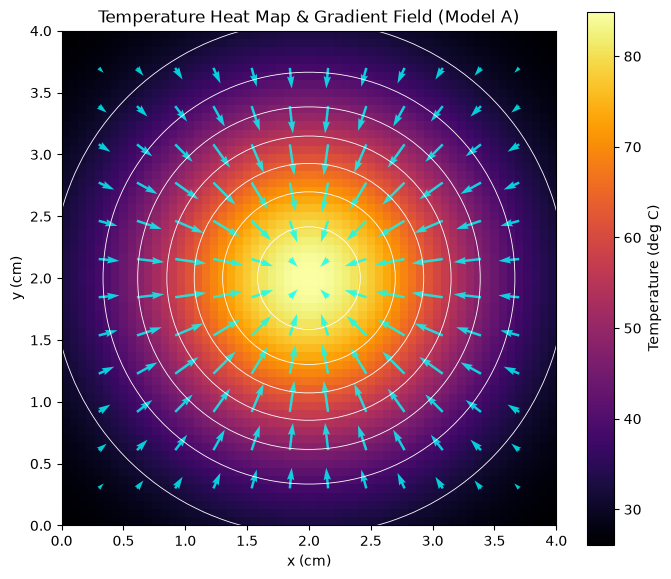

In [8]:
# Cell 8: Static Heat Map and Quiver Plot
xs = np.linspace(0.0, plate_a.L, 60)
ys = np.linspace(0.0, plate_a.L, 60)
X, Y = np.meshgrid(xs, ys)
Z = plate_a.get_temp(X, Y)

plt.figure(figsize=(7, 6))
im = plt.imshow(Z, origin='lower', extent=[0, plate_a.L, 0, plate_a.L], cmap='inferno')
plt.colorbar(im, label='Temperature (deg C)')
plt.contour(X, Y, Z, colors='white', linewidths=0.6)

# Overlay gradient vector arrows
q_xs = np.linspace(0.3, plate_a.L - 0.3, 12)
q_ys = np.linspace(0.3, plate_a.L - 0.3, 12)
QX, QY = np.meshgrid(q_xs, q_ys)
Tx, Ty = plate_a.get_grad(QX, QY)
plt.quiver(QX, QY, Tx, Ty, color='cyan', alpha=0.8)

plt.title('Temperature Heat Map & Gradient Field (Model A)')
plt.xlabel('x (cm)')
plt.ylabel('y (cm)')
plt.tight_layout()
plt.show()


## 8. Gradient Descent Cooling Trajectory Plot
We plot the path taken by the chip during gradient descent directly over the temperature field.


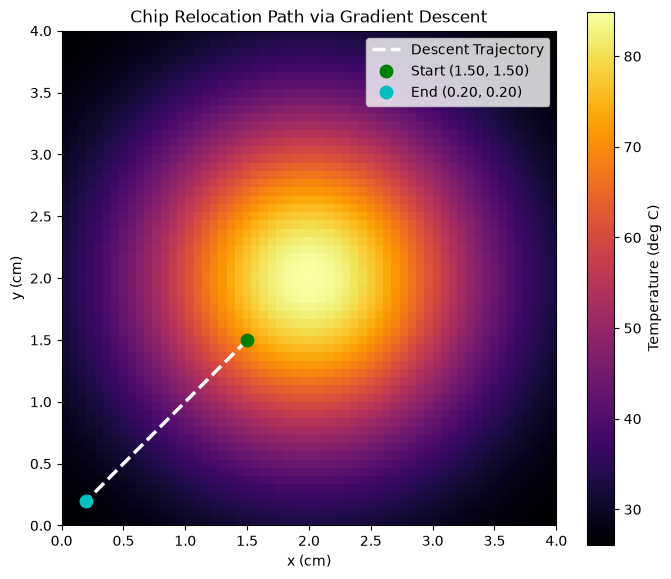

In [9]:
# Cell 9: Gradient Descent Trajectory Visualization
plt.figure(figsize=(7, 6))
im = plt.imshow(Z, origin='lower', extent=[0, plate_a.L, 0, plate_a.L], cmap='inferno')
plt.colorbar(im, label='Temperature (deg C)')

# Extract path coordinates
px = []
py = []
for pt in path:
    px.append(pt[0])
    py.append(pt[1])

plt.plot(px, py, 'w--', linewidth=2.5, label='Descent Trajectory')
plt.plot(px[0], py[0], 'go', markersize=9, label=f'Start ({px[0]:.2f}, {py[0]:.2f})')
plt.plot(px[-1], py[-1], 'co', markersize=9, label=f'End ({px[-1]:.2f}, {py[-1]:.2f})')

plt.title('Chip Relocation Path via Gradient Descent')
plt.xlabel('x (cm)')
plt.ylabel('y (cm)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()
